In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import re
import time
import zipfile
import os
import random

from pathlib import Path
from sklearn.model_selection import train_test_split

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)

TensorFlow version: 2.21.0
GPU available: True


re: supports text cleaning using regular expressions.

zipfile: extracts the downloaded dataset.

Path: handles file paths.

In [2]:
## Download the English–French dataset from the Anki ManyThings dataset, which is also used
## in the official Keras sequence-to-sequence tutorial

In [3]:
import urllib.request
import zipfile
import os

dataset_url = "https://www.manythings.org/anki/fra-eng.zip"
zip_path = "/content/fra-eng.zip"
extract_dir = "/content/fra_eng_data"

# Configure a User-Agent to prevent HTTP 406 Not Acceptable errors
req = urllib.request.Request(
    dataset_url,
    headers={'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)'}
)

print("Downloading dataset...")
with urllib.request.urlopen(req) as response, open(zip_path, 'wb') as out_file:
    out_file.write(response.read())

os.makedirs(extract_dir, exist_ok=True)

print("Extracting dataset...")
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_dir)

data_path = os.path.join(extract_dir, "fra.txt")

print("Dataset downloaded and extracted.")
print("Dataset path:", data_path)
print("File exists:", os.path.exists(data_path))

Extracting dataset...
Dataset downloaded and extracted.
Dataset path: /content/fra_eng_data/fra.txt
File exists: True


get_file(): downloads the dataset and caches it.



origin: specifies the download URL.



os.makedirs(): creates the extraction folder if it doesn't exist.



ZipFile(): opens the ZIP archive.



extractall(): extracts its contents.



os.path.exists(): checks whether the expected file exists.

In [4]:
## Load and inspect the sentences

with open(data_path, "r", encoding="utf-8") as file:
    lines = file.read().splitlines()

print("Total sentence pairs available:", len(lines))
print("\nFirst 5 raw records:")

for line in lines[:5]:
    print(line)

Total sentence pairs available: 240521

First 5 raw records:
Go.	Va !	CC-BY 2.0 (France) Attribution: tatoeba.org #2877272 (CM) & #1158250 (Wittydev)
Go.	Marche.	CC-BY 2.0 (France) Attribution: tatoeba.org #2877272 (CM) & #8090732 (Micsmithel)
Go.	En route !	CC-BY 2.0 (France) Attribution: tatoeba.org #2877272 (CM) & #8267435 (felix63)
Go.	Bouge !	CC-BY 2.0 (France) Attribution: tatoeba.org #2877272 (CM) & #9022935 (Micsmithel)
Hi.	Salut !	CC-BY 2.0 (France) Attribution: tatoeba.org #538123 (CM) & #509819 (Aiji)


open(): opens the text file.



encoding="utf-8": correctly reads French characters such as é and ç.



read(): reads the file contents.



splitlines(): separates the file into individual records.



lines[:5]: selects the first five records.

In [5]:
## Clean and prepare the text
MAX_SAMPLES = 15000

english_sentences = []
french_sentences = []

for line in lines:
    columns = line.split("\t")

    if len(columns) < 2:
        continue

    english = columns[0].strip().lower()
    french = columns[1].strip().lower()

    if not english or not french:
        continue

    english_sentences.append(english)
    french_sentences.append(french)

    if len(english_sentences) >= MAX_SAMPLES:
        break

# Add special tokens to French target sentences
french_sentences = [
    "startseq " + sentence + " endseq"
    for sentence in french_sentences
]

print("Prepared sentence pairs:", len(english_sentences))

for i in range(5):
    print("English:", english_sentences[i])
    print("French :", french_sentences[i])
    print()

Prepared sentence pairs: 15000
English: go.
French : startseq va ! endseq

English: go.
French : startseq marche. endseq

English: go.
French : startseq en route ! endseq

English: go.
French : startseq bouge ! endseq

English: hi.
French : startseq salut ! endseq



MAX_SAMPLES: controls the amount of data used.



strip(): removes leading and trailing whitespace.



lower(): converts text to lowercase.



append(): adds a sentence to a list.



startseq: marks the beginning of a French sequence.



endseq: marks the end of a French sequence.

In [6]:
## split the dataset
english_train,english_temp,french_train,french_temp=train_test_split(
    english_sentences,
    french_sentences,
    test_size=0.20,
    random_state=42
)
english_val, english_test, french_val, french_test = train_test_split(
    english_temp,
    french_temp,
    test_size=0.50,
    random_state=42
)



test_size=0.20: reserves 20% of the dataset for the temporary split.



random_state=42: makes the split reproducible.



english_train and french_train: sentence pairs used for learning.



english_val and french_val: used to monitor generalization during training.



english_test and french_test: reserved for final evaluation.

With 15,000 pairs, the approximate split is:
Dataset	Number of pairs
Training-12,000
Validation-1,500
Testing-1,500

In [7]:
from sklearn.model_selection import train_test_split
import tensorflow as tf

## Split the dataset first to guarantee variables exist
english_train, english_temp, french_train, french_temp = train_test_split(
    english_sentences,
    french_sentences,
    test_size=0.20,
    random_state=42
)
english_val, english_test, french_val, french_test = train_test_split(
    english_temp,
    french_temp,
    test_size=0.50,
    random_state=42
)

## Tokenize the sentences
MAX_LEN = 20
VOCAB_SIZE = 12000

english_vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=VOCAB_SIZE,
    output_mode="int",
    output_sequence_length=MAX_LEN
)

french_vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=VOCAB_SIZE,
    output_mode="int",
    output_sequence_length=MAX_LEN
)

english_vectorizer.adapt(
    tf.data.Dataset.from_tensor_slices(english_train).batch(256)
)
french_vectorizer.adapt(
    tf.data.Dataset.from_tensor_slices(french_train).batch(256)
)

print("English vocabulary size:", len(english_vectorizer.get_vocabulary()))
print("French vocabulary size:", len(french_vectorizer.get_vocabulary()))

English vocabulary size: 2497
French vocabulary size: 5632


TextVectorization: converts text into numerical sequences.



max_tokens: sets the maximum vocabulary size.



output_mode="int": outputs integer token IDs.



output_sequence_length=20: makes every sequence 20 tokens long.



adapt(): learns the vocabulary from training sentences.



get_vocabulary(): returns the learned vocabulary.


tensor_slices(english_train): Creates a TensorFlow dataset from your English training sentences.


batch(256): Groups up to 256 sentences into one batch for efficient processing.

In [8]:
## Convert sentences into numerical arrays
x_train=english_vectorizer(
      tf.constant(english_train)
).numpy()

x_val=english_vectorizer(
    tf.constant(english_val)
).numpy()
x_test = english_vectorizer(
    tf.constant(english_test)
).numpy()

target_train = french_vectorizer(
    tf.constant(french_train)
).numpy()

target_val = french_vectorizer(
    tf.constant(french_val)
).numpy()

tf.constant(): creates a TensorFlow tensor from the sentence list.



.numpy(): converts the resulting tensor into a NumPy array.



shape: displays the number of samples and tokens per sentence.

In [9]:
## Prepare decoder inputs and expected outputs

# Decoder receives the target sequence except its final token
decoder_train = target_train[:, :-1]
decoder_val = target_val[:, :-1]

# Expected output is shifted one position to the left
y_train = target_train[:, 1:]
y_val = target_val[:, 1:]

# Ignore padding positions when calculating the loss
sample_weights_train = (y_train != 0).astype("float32")
sample_weights_val = (y_val != 0).astype("float32")

print("Decoder input shape:", decoder_train.shape)
print("Expected output shape:", y_train.shape)

Decoder input shape: (12000, 19)
Expected output shape: (12000, 19)


[:, :-1]: selects every row except the final token position.



[:, 1:]: selects every row starting from the second token.



sample_weight: gives each output position a weight during loss calculation.



y_train != 0: identifies positions that are not padding.

In [10]:
## LSTM-Long Short-Term Memory Encoder, build the LSTM encoder–decoder model

EMBED_DIM = 128
LSTM_UNITS = 256

english_vocab_size = len(english_vectorizer.get_vocabulary())
french_vocab_size = len(french_vectorizer.get_vocabulary())

# Encoder
encoder_inputs = tf.keras.Input(
    shape=(MAX_LEN,),
    name="english_input"
)

encoder_embedding = tf.keras.layers.Embedding(
    input_dim=english_vocab_size,
    output_dim=EMBED_DIM,
    mask_zero=True,
    name="english_embedding"
)

encoder_lstm = tf.keras.layers.LSTM(
    LSTM_UNITS,
    return_state=True,
    name="encoder_lstm"
)

embedded_english = encoder_embedding(encoder_inputs)

_, encoder_h, encoder_c = encoder_lstm(embedded_english)

# Decoder
decoder_inputs = tf.keras.Input(
    shape=(MAX_LEN - 1,),
    name="french_input"
)

decoder_embedding = tf.keras.layers.Embedding(
    input_dim=french_vocab_size,
    output_dim=EMBED_DIM,
    mask_zero=True,
    name="french_embedding"
)

decoder_lstm = tf.keras.layers.LSTM(
    LSTM_UNITS,
    return_sequences=True,
    return_state=True,
    name="decoder_lstm"
)

embedded_french = decoder_embedding(decoder_inputs)

decoder_outputs, _, _ = decoder_lstm(
    embedded_french,
    initial_state=[encoder_h, encoder_c]
)

output_layer = tf.keras.layers.Dense(
    french_vocab_size,
    activation="softmax",
    name="word_probabilities"
)

predictions = output_layer(decoder_outputs)
model = tf.keras.Model(
    inputs=[encoder_inputs, decoder_inputs],
    outputs=predictions
)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ english_input       │ (None, 20)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ french_input        │ (None, 19)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ english_embedding   │ (None, 20, 128)   │    319,616 │ english_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 20)        │          0 │ english_input[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ french_embedding    │ (None, 19, 128)   │    720,896 │ french_input[0][… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm (LSTM) │ [(None, 256),     │    394,240 │ english_embeddin… │
│                     │ (None, 256),      │            │ not_equal[0][0]   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm (LSTM) │ [(None, 19, 256), │    394,240 │ french_embedding… │
│                     │ (None, 256),      │            │ encoder_lstm[0][… │
│                     │ (None, 256)]      │            │ encoder_lstm[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ word_probabilities  │ (None, 19, 5632)  │  1,447,424 │ decoder_lstm[0][… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 3,276,416 (12.50 MB)

 Trainable params: 3,276,416 (12.50 MB)

 Non-trainable params: 0 (0.00 B)

Embedding: converts token IDs into dense numerical vectors.



mask_zero=True: tells the sequence layers to ignore padding tokens.



LSTM: learns patterns across a sequence while maintaining internal states.



return_state=True: returns the LSTM's hidden state and cell state.



return_sequences=True: returns an output for every decoder time step.



initial_state: initializes the decoder using the encoder's learned states.



Dense: maps decoder outputs to scores for the French vocabulary.



softmax: converts the scores into probabilities over possible next tokens.

How the architecture works
1. The encoder reads the English token sequence.
2. It produces two internal states, encoder_h and encoder_c.
3. The decoder receives the French sequence shifted by one position.
4. The encoder's states initialize the decoder.
5. The decoder predicts a probability distribution for each next French token.

Why two LSTM states?
- h is the hidden state, which represents the current output and learned context.
- c is the cell state, which carries longer-term information through the sequence.

Understand Sigmoid, Tanh and Softmax
You requested these activation functions, so here is how they relate to the model.
Sigmoid
\[
\sigma(x)=\frac{1}{1+e^{-x}}
\]

Outputs values between 0 and 1. LSTM gates use sigmoid to control how much information is retained, forgotten, or exposed.


Tanh
\[
\tanh(x)\in[-1,1]
\]

Creates positive and negative state values. A standard LSTM uses tanh when updating and producing cell-related information.


Softmax
\[
P_i=\frac{e^{z_i}}{\sum_j e^{z_j}}
\]

In [11]:
## Compile the model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["sparse_categorical_accuracy"]
)

compile(): configures the model's learning process.



optimizer="adam": updates weights using an adaptive optimization method.



sparse_categorical_crossentropy: measures the error when the correct next token is represented by an integer ID.



sparse_categorical_accuracy: measures the proportion of predicted token IDs that match the expected IDs.

In [12]:
## Train the LSTM

EPOCHS = 10
BATCH_SIZE = 64

start_time = time.time()

history = model.fit(
    [x_train, decoder_train],
    y_train,
    sample_weight=sample_weights_train,
    validation_data=(
        [x_val, decoder_val],
        y_val,
        sample_weights_val
    ),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1
)
training_time = time.time() - start_time
print(f"Training time: {training_time:.2f} seconds")

Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 13s 36ms/step - loss: 4.4491 - sparse_categorical_accuracy: 0.2214 - val_loss: 3.9067 - val_sparse_categorical_accuracy: 0.2428
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 31ms/step - loss: 3.5138 - sparse_categorical_accuracy: 0.2771 - val_loss: 3.5197 - val_sparse_categorical_accuracy: 0.3019
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step - loss: 3.0623 - sparse_categorical_accuracy: 0.3321 - val_loss: 3.2214 - val_sparse_categorical_accuracy: 0.3408
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step - loss: 2.7274 - sparse_categorical_accuracy: 0.3627 - val_loss: 3.0222 - val_sparse_categorical_accuracy: 0.3645
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - loss: 2.4466 - sparse_categorical_accuracy: 0.3928 - val_loss: 2.8563 - val_sparse_categorical_accuracy: 0.3853
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step - loss: 2.2006 - sparse_categorical_accuracy: 0.4153 - val_loss: 2.7498 - val_sparse_categorical_accuracy: 0.3

batch_size=64: processes 64 sentence pairs per batch.



validation_data: checks performance on unseen validation pairs.



sample_weight: prevents padded positions from contributing to the loss.



history: stores the loss and metric values from each epoch.



training_time: measures the total training duration.

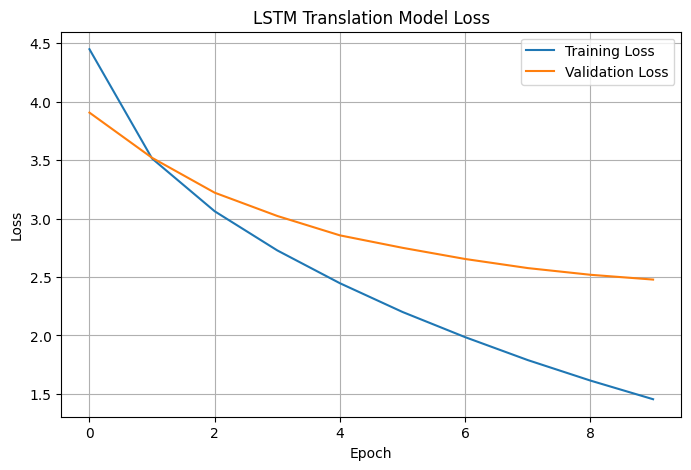

In [13]:
## Visualize training loss

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LSTM Translation Model Loss")
plt.legend()
plt.grid(True)
plt.show()

How to interpret it
- Decreasing training loss means the model is getting better at predicting the target tokens in training data.
- Decreasing validation loss indicates improving performance on unseen validation pairs.
- If training loss continues decreasing but validation loss increases, the model may be overfitting.

In [14]:
## Create an inference model for translation

encoder_model = tf.keras.Model(
    encoder_inputs,
    [encoder_h, encoder_c]
)

single_token_input = tf.keras.Input(shape=(1,), name="next_french_token")
state_h_input = tf.keras.Input(shape=(LSTM_UNITS,), name="hidden_state_input")
state_c_input = tf.keras.Input(shape=(LSTM_UNITS,), name="cell_state_input")

embedded_token = decoder_embedding(single_token_input)

step_output, next_h, next_c = decoder_lstm(
    embedded_token,
    initial_state=[state_h_input, state_c_input]
)

step_probabilities = output_layer(step_output)

decoder_model = tf.keras.Model(
    inputs=[single_token_input, state_h_input, state_c_input],
    outputs=[step_probabilities, next_h, next_c]
)

print("Encoder and decoder inference models created.")

Encoder and decoder inference models created.


In [16]:
## Define the translation inference function

# Get vocabularies and build mappings
english_vocab = english_vectorizer.get_vocabulary()
french_vocab = french_vectorizer.get_vocabulary()

french_id_to_token = {idx: token for idx, token in enumerate(french_vocab)}

def translate_sentence(sentence):
    # Vectorize the input English sentence
    input_seq = english_vectorizer(tf.constant([sentence])).numpy()

    # Get initial state vectors from the encoder
    states_value = encoder_model.predict(input_seq, verbose=0)

    # Generate empty target sequence of length 1 containing the start token ID
    start_token_id = french_vocab.index("startseq") if "startseq" in french_vocab else 2
    end_token_id = french_vocab.index("endseq") if "endseq" in french_vocab else 3

    target_seq = np.zeros((1, 1))
    target_seq[0, 0] = start_token_id

    decoded_sentence = []

    for _ in range(MAX_LEN):
        output_tokens, h, c = decoder_model.predict(
            [target_seq] + states_value, verbose=0
        )

        # Sample the next token ID with the highest probability
        sampled_token_index = np.argmax(output_tokens[0, 0, :])
        sampled_token = french_id_to_token.get(sampled_token_index, "")

        if sampled_token == "endseq" or not sampled_token:
            break

        decoded_sentence.append(sampled_token)

        # Update the target sequence to contain the predicted token ID
        target_seq[0, 0] = sampled_token_index

        # Update state values
        states_value = [h, c]

    return " ".join(decoded_sentence)

encoder_model: converts an English input into the initial decoder states.



single_token_input: accepts one French token at a time.



state_h_input and state_c_input: receive the previous decoder states.



next_h and next_c: are the updated states after processing the current token.



Shared layers: reuse the trained embedding, LSTM and output weights rather than creating a new, untrained model.

In [15]:
## User-input English-to-French translation
while True:
    user_sentence = input(
        "\nEnter an English sentence (or type 'exit' to stop): "
    ).strip()

    if user_sentence.lower() == "exit":
        print("Translation program stopped.")
        break

    if not user_sentence:
        print("Please enter a sentence.")
        continue

    start = time.time()

    french_translation = translate_sentence(user_sentence)

    elapsed = time.time() - start

    print("English :", user_sentence)
    print("French  :", french_translation)
    print(f"Time taken: {elapsed:.4f} seconds")



Enter an English sentence (or type 'exit' to stop): lets go to the party


NameError: name 'translate_sentence' is not defined

In [17]:
# Test translation on a custom sentence
test_sentence = "let's go to the party"
french_translation = translate_sentence(test_sentence)

print("English :", test_sentence)
print("French  :", french_translation)

English : let's go to the party
French  : faisons la maison


get_vocabulary(): retrieves the token vocabulary.



token_to_id: maps tokens to numerical IDs.



id_to_token: maps predicted IDs back to words.



argmax(): selects the token with the highest predicted probability.



for _ in range(...): generates tokens until the maximum length is reached.



break: stops generation when the end token or padding is encountered

In [18]:
%pip -q install nltk

In [19]:
## BLEU— Bilingual Evaluation Understudy,A metric used to evaluate machine translation quality, such as English-to-French translation.
# Evaluate translation quality with BLEU
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
import time

# Begin with 100 test examples to keep evaluation manageable
NUM_BLEU_EXAMPLES = min(100, len(english_test))

references = []
predictions = []

smooth = SmoothingFunction().method1
start_time = time.time()

for i in range(NUM_BLEU_EXAMPLES):
    reference_text = french_test[i]
    predicted_text = translate_sentence(english_test[i])

    # Remove special sequence markers
    reference_text = reference_text.replace("startseq", "").replace("endseq", "")
    predicted_text = predicted_text.replace("startseq", "").replace("endseq", "")

    # BLEU expects tokenized words
    references.append([reference_text.strip().split()])
    predictions.append(predicted_text.strip().split())

bleu_score = corpus_bleu(
    references,
    predictions,
    smoothing_function=smooth
)

evaluation_time = time.time() - start_time

print(f"Number of test sentences: {NUM_BLEU_EXAMPLES}")
print(f"Corpus BLEU score: {bleu_score:.4f}")
print(f"Corpus BLEU percentage: {bleu_score * 100:.2f}%")
print(f"Evaluation time: {evaluation_time:.2f} seconds")

Number of test sentences: 100
Corpus BLEU score: 0.0520
Corpus BLEU percentage: 5.20%
Evaluation time: 55.02 seconds


corpus_bleu(): calculates one BLEU score across all evaluated sentences.



references: the actual French translations, tokenized into words. Each sentence has a list of reference translations.



predictions: the French translations generated by your model.



SmoothingFunction().method1: helps avoid a zero score when some higher-order word n-grams do not overlap.



min(100, len(english_test)): evaluates up to 100 sentences, or fewer if the test set is smaller.



evaluation_time: measures how long the evaluation loop takes.

In [20]:
## Measure translation inference speed

# Part 18: Measure single-sentence inference speed

import time

test_sentence = "How are you today?"

# Warm-up run
_ = translate_sentence(test_sentence)

NUM_RUNS = 10
start_time = time.time()

for _ in range(NUM_RUNS):
    _ = translate_sentence(test_sentence)

total_time = time.time() - start_time
average_time = total_time / NUM_RUNS

print("Test sentence:", test_sentence)
print(f"Total time for {NUM_RUNS} translations: {total_time:.4f} seconds")
print(f"Average time per translation: {average_time:.4f} seconds")
print(f"Approximate translations per second: {1 / average_time:.2f}")

Test sentence: How are you today?
Total time for 10 translations: 11.3075 seconds
Average time per translation: 1.1308 seconds
Approximate translations per second: 0.88


warm-up run: runs the model once before timing, reducing the effect of initial setup overhead.



NUM_RUNS: number of repeated translations.



average_time: total measured time divided by the number of runs.



translations per second: approximate throughput for this repeated single-sentence test.

In [21]:
## Save the text vectorizers
## Save English and French vectorizers

ENGLISH_VECTORIZER_PATH = "/content/english_vectorizer.keras"
FRENCH_VECTORIZER_PATH = "/content/french_vectorizer.keras"

english_vectorizer_model = tf.keras.Sequential([
    tf.keras.Input(shape=(), dtype=tf.string),
    english_vectorizer
])

french_vectorizer_model = tf.keras.Sequential([
    tf.keras.Input(shape=(), dtype=tf.string),
    french_vectorizer
])

english_vectorizer_model.save(ENGLISH_VECTORIZER_PATH)
french_vectorizer_model.save(FRENCH_VECTORIZER_PATH)

print("English vectorizer saved:", ENGLISH_VECTORIZER_PATH)
print("French vectorizer saved:", FRENCH_VECTORIZER_PATH)

English vectorizer saved: /content/english_vectorizer.keras
French vectorizer saved: /content/french_vectorizer.keras


In [23]:
## Save the trained LSTM model
model.save("/content/english_french_lstm.keras")

## Confirm that all three files exist
import os

for filename in [
    "english_french_lstm.keras",
    "english_vectorizer.keras",
    "french_vectorizer.keras"
]:
    filepath = f"/content/{filename}"
    print(filename, "->", os.path.exists(filepath))

english_french_lstm.keras -> True
english_vectorizer.keras -> True
french_vectorizer.keras -> True


In [24]:
from google.colab import files

files.download("/content/english_french_lstm.keras")
files.download("/content/english_vectorizer.keras")
files.download("/content/french_vectorizer.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>